# Task4 — Fourier amplitude expert

ต่อจาก matched-fold EfficientNet-B0 อีก **6 epochs × 5 folds**, และ full model อีก 6 epochs เมื่อผ่าน development/audit. ไม่มีการดาวน์โหลด weights เพิ่ม ใช้ checkpoint ที่มีอยู่แล้ว

Run All: ตรวจ Train/โมเดล → ฝึก Fourier expert → เปรียบเทียบกับ baseline ที่ได้ Public 0.81047 → audit → full refit ถ้าผ่าน. ไม่อ่าน Test และไม่สร้าง submission ในเล่มนี้

Donor มาจาก training fold เดียวกันเท่านั้น; ไม่มีภาพ validation/Test เป็น donor. 50% presentations ผสม amplitude ทั้ง spectrum ด้วย coefficient Uniform(0, .3) โดยคง source phase ก่อน clip; อีก 50% ใช้ compound augmentation เดิม. ผสมก่อน padding และใช้ rotation อ่อน ±10°. การคง phase ไม่รับรองว่า semantic label จะคงเดิมทุกภาพ ต้องตรวจภาพตัวอย่าง

แนวคิดจาก [FACT, CVPR 2021](https://openaccess.thecvf.com/content/CVPR2021/html/Xu_A_Fourier-Based_Framework_for_Domain_Generalization_CVPR_2021_paper.html); นี่เป็น amplitude-mixing variant ไม่มี teacher/consistency loss ของ FACT เต็มรูปแบบ

การเปรียบเทียบนี้วัดประโยชน์ของ expert ทั้งสูตร ไม่ได้แยกผล Fourier ออกจากการฝึกต่ออีก 6 epochs; หากต้องการ causal ablation ต้องมี control ที่ฝึกต่อโดยไม่มี Fourier ด้วย

ค่าทั้งหมดกำหนดก่อนดูผล ไม่ปรับตาม Test. OOF/audit ถูกใช้หลายครั้งแล้ว ผลยังเป็น exploratory ไม่ใช่ independent validation.

In [5]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import pandas as pd
import torch
from dataclasses import asdict
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'Task4/models/image_training.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from Task4.models import image_fourier_training as training
from Task4.models import image_fourier_evaluation as evaluation
from Task4.models import image_compound_validation as validation
from Task4.models.image_audit import make_folds
from Task4.models.image_compound_transforms import CONDITIONS
RAW=ROOT/'Task4/data/raw'
AUDIT=ROOT/'Task4/data/audit/followup_v2'
OUT=ROOT/'Task4/models/results/fourier_expert_v1'
BATCH_SIZE=32
NUM_WORKERS=0
RUN_FULL_REFIT=True
NAME='fourier_efficientnet6'
print('Device:',training.get_device())
if training.get_device().type=='cpu':raise RuntimeError('CPU training would be slow: select the project kernel with MPS/CUDA available.')
display(asdict(training.RECIPES[NAME]))

Device: mps


{'architecture': 'efficientnet_b0',
 'epochs': 6,
 'backbone_lr': 2e-05,
 'head_lr': 2e-05,
 'weight_decay': 0.0001,
 'schedule': 'cosine',
 'warmup_epochs': 1,
 'augmentation': 'fourier_amplitude',
 'label_smoothing': 0.0,
 'seed': 42,
 'balance': 'weighted_loss',
 'jsd_weight': 0.0,
 'compound_probability': 0.6,
 'fourier_probability': 0.5,
 'amplitude_max': 0.3}

## 1. Verify Train, fold identity และแหล่งข้อมูล
ตรวจไฟล์ Train กับ audit hashes เดิม ไม่แตะ Test. ถ้า settings เปลี่ยนให้ใช้ RUN directory ใหม่ ห้าม resume ปะปน config.

In [6]:
train=pd.read_csv(RAW/'train.csv')
groups=pd.read_parquet(AUDIT/'train_groups.parquet')
assert train.id.is_unique and train.label.notna().all()
assert all(np.array_equal(train[c],groups[c]) for c in ['id','file_name','label'])
metadata=pd.read_parquet(AUDIT/'images.parquet',filters=[('split','=','train')]).set_index('id').loc[train.id]
assert metadata.split.eq('train').all()
inventory=hashlib.sha256()
for row in metadata.itertuples():
    assert Path(row.file_name).name==row.file_name
    digest=validation.sha(RAW/'train'/row.file_name)
    assert digest==row.sha256, f'Changed Train image: {row.file_name}'
    inventory.update(f'{row.file_name}/{digest}'.encode())
folds=make_folds(groups,mode='near',n_splits=5,seed=42)
fold_hash=hashlib.sha256(b''.join(v.astype('int64').tobytes() for _,v in folds)).hexdigest()
assert fold_hash==json.loads((ROOT/'Task4/models/results/heavy_balance_v1/settings.json').read_text())['fold_hash']
reference_hashes={}
for fold,(fit,valid) in enumerate(folds,1):
    assert not np.intersect1d(fit,valid).size
    assert not set(groups.iloc[fit].near_group)&set(groups.iloc[valid].near_group)
    for path in evaluation.references(ROOT,fold):
        signature=json.loads((path.parent/'signature.json').read_text())
        assert signature['data_signature']==validation.sha_frame(groups.iloc[fit])
        reference_hashes[str(path.relative_to(ROOT))]=validation.sha(path)
        frame=pd.read_parquet(path.parent/'oof.parquet')
        assert frame.id.tolist()==groups.iloc[valid].id.tolist()
        assert np.array_equal(frame.true,groups.iloc[valid].label)
        reference_hashes[str((path.parent/'oof.parquet').relative_to(ROOT))]=validation.sha(path.parent/'oof.parquet')
sources={p.name:validation.sha(p) for p in (ROOT/'Task4/models').glob('image_*.py')}
settings={'recipe':asdict(training.RECIPES[NAME]),'batch_size':BATCH_SIZE,'workers':NUM_WORKERS,
          'train_manifest':validation.sha(RAW/'train.csv'),'inventory':inventory.hexdigest(),'fold_hash':fold_hash,
          'references':reference_hashes,'sources':sources,'torch':str(torch.__version__),'device':str(training.get_device())}
OUT.mkdir(parents=True,exist_ok=True)
if (OUT/'settings.json').exists():assert json.loads((OUT/'settings.json').read_text())==settings,'Settings changed: use a new OUT'
else:
    assert not any(OUT.iterdir()),'Nonempty OUT without settings'
    validation.write_json(OUT/'settings.json',settings)
print('Train verified:',len(train),'rows; Test unopened')

Train verified: 31546 rows; Test unopened


### ภาพตัวอย่างจาก training fold1 เท่านั้น
ซ้าย source, กลาง donor, ขวา amplitude mix ที่ coefficient .3 ก่อน geometry/padding; ไม่แก้ label

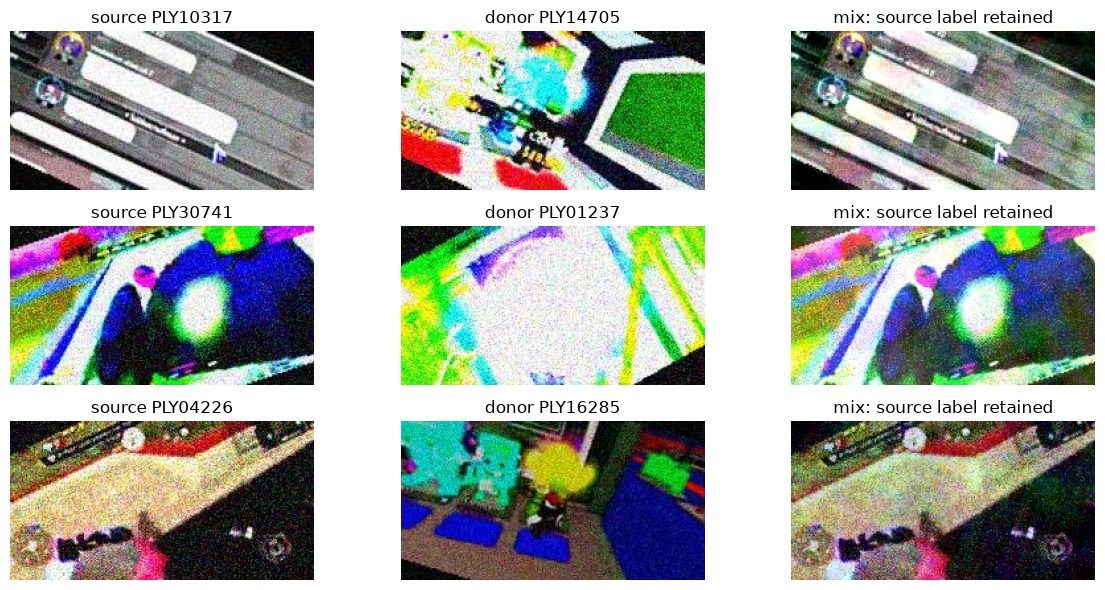

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
from torchvision.transforms import functional as F
from Task4.models.image_fourier_transforms import mix_amplitude
sample=groups.iloc[folds[0][0]].sample(6,random_state=2026)
fig,axes=plt.subplots(3,3,figsize=(12,6))
for k in range(3):
    a,b=sample.iloc[2*k],sample.iloc[2*k+1]
    with Image.open(RAW/'train'/a.file_name) as f:x=F.to_tensor(f.convert('RGB'))
    with Image.open(RAW/'train'/b.file_name) as f:y=F.to_tensor(f.convert('RGB'))
    mixed=mix_amplitude(x,y,.3)
    for ax,img,title in zip(axes[k],[x,y,mixed],[f'source {a.id}',f'donor {b.id}','mix: source label retained']):
        ax.imshow(img.permute(1,2,0));ax.set_title(title);ax.axis('off')
plt.tight_layout();plt.show()

## 2. Train fixed 6 epochs × 5 folds และ paired validation

Checkpoint ทุก epoch และ final model หลังจบ; resume จะทำ epoch ที่ค้างใหม่. Warm-start ต้องตรง training rows ของ fold นั้น ห้ามใช้ full model เริ่ม OOF.

เทียบสามสูตร: baseline เดิม (.25 compound ResNet + .25 sampler ResNet + .50 EfficientNet), Fourier expert เดี่ยว และ **blend25 = .75 baseline + .25 Fourier**. สูตร blend25 เท่ากับ .1875/.1875/.375/.25 ของสี่โมเดล ตามลำดับ. ไม่ค้นน้ำหนักอื่น

ใช้ stress conditions และ deterministic corrupted pixels เดิม. วัดเวลา epoch แรกจริงก่อนประมาณทั้งเล่ม; มี CV 30 epochs และ full อีก 6 ถ้าผ่าน. FFT ทำบน CPU เฉพาะภาพฝึก และไม่ทำ Fourier augmentation ตอน validation/inference.

In [8]:
oof={};scores=[];overlaps=[]
started=time.monotonic()
for fold in range(1,6):
    print(f'\nFourier expert fold {fold}/5',flush=True)
    oof[fold]=training.run_fold(RAW,groups,folds,NAME,fold,OUT,BATCH_SIZE,NUM_WORKERS, init_path=ROOT/'Task4/models/results/backbone_diversity_v1/efficientnet_compound18'/f'fold{fold}'/'model.pt')
    score,overlap=evaluation.compare(ROOT,RAW,groups,folds,OUT,fold,oof[fold])
    scores.append(score);overlaps.append(overlap)
    display(evaluation.summarize(score))
    history=json.loads((OUT/NAME/f'fold{fold}'/'history.json').read_text())
    seconds=np.mean([h['seconds'] for h in history[-3:]])
    print('Approx remaining CV TRAIN minutes (excludes validation):',round(seconds*6*(5-fold)/60,1))
all_scores=pd.concat(scores,ignore_index=True)
all_overlap=pd.concat(overlaps,ignore_index=True)
all_scores.to_parquet(OUT/'development_scores.parquet',index=False)
all_overlap.to_parquet(OUT/'development_overlap.parquet',index=False)
print('CV elapsed hours:',round((time.monotonic()-started)/3600,2))


Fourier expert fold 1/5


suite,compound,original,single
procedure,,,
baseline,0.944725,0.986331,0.977201
blend25,0.947717,0.986396,0.978398
fourier,0.938986,0.978416,0.975224


Approx remaining CV TRAIN minutes (excludes validation): 89.3

Fourier expert fold 2/5


suite,compound,original,single
procedure,,,
baseline,0.955820,0.983375,0.985600
blend25,0.956491,0.984667,0.985591
fourier,0.951149,0.977872,0.984584


Approx remaining CV TRAIN minutes (excludes validation): 66.6

Fourier expert fold 3/5


suite,compound,original,single
procedure,,,
baseline,0.948277,0.984449,0.981614
blend25,0.947906,0.983111,0.978815
fourier,0.934587,0.976999,0.970399


Approx remaining CV TRAIN minutes (excludes validation): 48.7

Fourier expert fold 4/5
fold4 epoch 1 / 6 loss 0.06569 seconds 279.6
fold4 epoch 2 / 6 loss 0.05603 seconds 274.6
fold4 epoch 3 / 6 loss 0.05671 seconds 254.3
fold4 epoch 4 / 6 loss 0.05415 seconds 256.7
fold4 epoch 5 / 6 loss 0.04655 seconds 257.7
fold4 epoch 6 / 6 loss 0.0487 seconds 256.5
stress fold4 gaussian_1
stress fold4 gaussian_2
stress fold4 speckle_1
stress fold4 speckle_2
stress fold4 blur_1
stress fold4 blur_2
stress fold4 jpeg_1
stress fold4 jpeg_2
stress fold4 dark_1
stress fold4 dark_2
stress fold4 compound_dark_noise
stress fold4 compound_color_noise
stress fold4 compound_rotation_dark
stress fold4 compound_bright_color
stress fold4 compound_dark_color_noise
stress fold4 compound_rotation_color_noise


suite,compound,original,single
procedure,,,
baseline,0.942175,0.980890,0.981004
blend25,0.946493,0.982045,0.982594
fourier,0.948930,0.979604,0.981389


Approx remaining CV TRAIN minutes (excludes validation): 25.7

Fourier expert fold 5/5
fold5 epoch 1 / 6 loss 0.06708 seconds 249.5
fold5 epoch 2 / 6 loss 0.05731 seconds 227.1
fold5 epoch 3 / 6 loss 0.05492 seconds 222.6
fold5 epoch 4 / 6 loss 0.0532 seconds 223.8
fold5 epoch 5 / 6 loss 0.05553 seconds 223.6
fold5 epoch 6 / 6 loss 0.05266 seconds 223.6
stress fold5 gaussian_1
stress fold5 gaussian_2
stress fold5 speckle_1
stress fold5 speckle_2
stress fold5 blur_1
stress fold5 blur_2
stress fold5 jpeg_1
stress fold5 jpeg_2
stress fold5 dark_1
stress fold5 dark_2
stress fold5 compound_dark_noise
stress fold5 compound_color_noise
stress fold5 compound_rotation_dark
stress fold5 compound_bright_color
stress fold5 compound_dark_color_noise
stress fold5 compound_rotation_color_noise


suite,compound,original,single
procedure,,,
baseline,0.940842,0.984526,0.981418
blend25,0.941151,0.984650,0.980597
fourier,0.937780,0.981542,0.976985


Approx remaining CV TRAIN minutes (excludes validation): 0.0
CV elapsed hours: 0.93


## 3. Evidence และเลือกสูตรจาก development เท่านั้น
เกณฑ์เป็น project heuristic: original ลดไม่เกิน .001; stress แบบเฉลี่ยเท่ากันต่อ family เพิ่ม ≥.002 และชนะ ≥4/5 folds; per-class ลดไม่เกิน .01; condition ลดไม่เกิน .02. ไม่บังคับ single-corruption เพิ่ม .005 เหมือน gate เก่า เพราะใกล้เพดาน แต่ยังจำกัด regression.

In [9]:
display(evaluation.summarize(all_scores))
display(all_overlap[all_overlap.condition.eq('original')])
selection=evaluation.select(all_scores)
validation.write_json(OUT/'development_selection.json',selection)
display(selection)
# Class-specific OOF and difficult quality slice evidence (no Test)
quality=pd.read_parquet(ROOT/'Task4/eda/advanced_train_v1/accounts.parquet').set_index('id')
rows=[]
for fold,frame in oof.items():
    base_frames=[pd.read_parquet(p.parent/'oof.parquet') for p in evaluation.references(ROOT,fold)]
    reference_probs=[training.probabilities(f,'tta') for f in base_frames]
    bp=.25*reference_probs[0]+.25*reference_probs[1]+.5*reference_probs[2]
    cp=training.probabilities(frame,'tta');q=quality.loc[frame.id]
    # Derive slice threshold from TRAINING fold quality only, then apply to held-out.
    fit,_=folds[fold-1]
    cutoff=quality.loc[groups.iloc[fit].id,'gradient_y'].quantile(.2)
    for proc,prob in [('baseline',bp),('fourier',cp),('blend25',.75*bp+.25*cp)]:
        masks={'all':np.ones(len(frame),dtype=bool),'low_gradient':q.gradient_y.to_numpy()<=cutoff}
        for label in range(5):masks[f'class_{label}']=frame.true.to_numpy()==label
        for label,mask in masks.items():
            rows.append({'fold':fold,'procedure':proc,'slice':label,'rows':int(mask.sum()),
                         'errors':int((prob.argmax(1)[mask]!=frame.true.to_numpy()[mask]).sum())})
slices=pd.DataFrame(rows);slices.to_parquet(OUT/'quality_class_slices.parquet',index=False)
summary=slices.groupby(['procedure','slice'])[['rows','errors']].sum()
summary['error_rate']=summary.errors/summary.rows
display(summary)

suite,compound,original,single
procedure,,,
baseline,0.946368,0.983914,0.981367
blend25,0.947951,0.984174,0.981199
fourier,0.942286,0.978887,0.977716


,fold,phase,condition,rows,baseline_errors,candidate_errors,both_wrong,candidate_fixes,candidate_breaks
0,1,development,original,6310,70,112,57,13,55
17,2,development,original,6309,88,113,68,20,45
34,3,development,original,6309,86,127,75,11,52
51,4,development,original,6309,96,103,72,24,31
68,5,development,original,6309,81,95,63,18,32


{'chosen': 'baseline',
 'reports': {'fourier': {'original_gain': -0.005027496900384176,
   'stress_family_gain': -0.0037229603098258316,
   'stress_fold_wins': 1,
   'worst_class_gain': -0.010155193351599512,
   'worst_condition_gain': -0.009142390372971576,
   'passed': False},
  'blend25': {'original_gain': 0.00025963226271568106,
   'stress_family_gain': 0.00012354243079504656,
   'stress_fold_wins': 3,
   'worst_class_gain': -0.0008986334619666802,
   'worst_condition_gain': -0.0012037805816978331,
   'passed': False}},
 'rule': 'original >= -0.001; family-balanced stress >= +0.002; wins >=4/5; per-class >= -0.01; condition >= -0.02',
 'exploratory_reused_oof': True}

rows  errors  error_rate
procedure slice                                  
baseline  all           31546     421    0.013346
          class_0       12429     104    0.008368
          class_1        4407      71    0.016111
          class_2        5596      74    0.013224
          class_3        5926     100    0.016875
          class_4        3188      72    0.022585
          low_gradient   6308     199    0.031547
blend25   all           31546     410    0.012997
          class_0       12429     100    0.008046
          class_1        4407      71    0.016111
          class_2        5596      76    0.013581
          class_3        5926      97    0.016369
          class_4        3188      66    0.020703
          low_gradient   6308     197    0.031230
fourier   all           31546     550    0.017435
          class_0       12429     161    0.012954
          class_1        4407      84    0.019061
          class_2        5596      90    0.016083
          class_3        5926     143    0.024131
          class_4        3188      72    0.022585
          low_gradient   6308     271    0.042961

## 4. Fixed audit veto
ประเมินสูตรที่เลือกไว้แล้ว ไม่เลือกผู้ชนะใหม่ตาม audit หากไม่ผ่านจะเก็บ baseline. ชุด audit ถูกใช้ในงานก่อนหน้าแล้ว ไม่ถือเป็น untouched holdout.

In [10]:
audit_result={'passed':False,'reason':'Development did not select a candidate'}
if selection['chosen']!='baseline':
    audit_parts=[]
    for fold in range(1,6):
        score,_=evaluation.compare(ROOT,RAW,groups,folds,OUT,fold,oof[fold],phase='audit')
        audit_parts.append(score)
    audit_scores=pd.concat(audit_parts,ignore_index=True)
    audit_scores.to_parquet(OUT/'audit_scores.parquet',index=False)
    audit_result=evaluation.audit(audit_scores,selection['chosen'])
    display(evaluation.summarize(audit_scores))
validation.write_json(OUT/'audit_decision.json',audit_result)
display(audit_result)

{'passed': False, 'reason': 'Development did not select a candidate'}

## 5. Full refit และบันทึกโมเดล

ต่อจาก EfficientNet full checkpoint อีก 6 epochs บน Train ทั้งหมด เมื่อ development/audit ผ่านเท่านั้น. donor pool ตอนนี้คือ Train ทั้งหมด. ไม่เปิด Test ใน notebook นี้; ส่งผลมาให้ตรวจแล้วจึงสร้าง submission

ถ้าเลือก blend25 ต้องใช้ full checkpoint ของโมเดลเดิมทั้งสามร่วมด้วย ไม่เอา full weights ไปสร้าง OOF.

In [11]:
full_path=None
if RUN_FULL_REFIT and selection['chosen']!='baseline' and audit_result['passed']:
    full_path=training.fit_fixed(RAW,groups,training.RECIPES[NAME],OUT/NAME/'full',BATCH_SIZE,NUM_WORKERS, init_path=ROOT/'Task4/models/results/backbone_diversity_v1/efficientnet_compound18/full/model.pt')
    validation.write_json(OUT/'ready_for_review.json',{
        'procedure':selection['chosen'],'fourier_model':str(full_path),'sha256':validation.sha(full_path),
        'test_used':False,'submission_created':False,
        'selection':selection,'audit':audit_result})
    print('Saved full model:',full_path)
else:
    print('No full refit: inspect development/audit results above. Existing baseline preserved.')

No full refit: inspect development/audit results above. Existing baseline preserved.
